# House Prices

First dataset I touched in 2022.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))


import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from src.prices.config import Cfg
from src.prices.data_ingestion import DataIngestion

sns.set_theme(style="whitegrid")

df = DataIngestion().load(Cfg.data_path)
display(df.head())

,price,year,age,beds,baths,home_size,parcel_size,pool,dist_cbd,dist_lakes,x_coord,y_coord
0,250412,2001,0,5,3.0,3217,11521,1,12351.12,4789.03,574225.4,1521524
1,195068,2000,4,4,3.0,2770,6199,1,18574.37,6745.57,527637.2,1470564
2,232224,2002,7,4,2.5,2191,11130,1,17519.73,420.27,499076.7,1486071
3,90481,2003,33,3,1.0,1025,8881,0,9970.23,774.06,565786.8,1541718
4,297092,2000,0,4,3.0,2790,14932,0,13298.67,531.99,493347.9,1517546


## Summary statistics

Count, mean, spread and range for every column.

In [2]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
price,10000.0,182222.84,143105.41,7021.00,113979.00,151028.00,209366.00,3662668.00
year,10000.0,2002.34,1.53,2000.00,2001.00,2002.00,2004.00,2005.00
age,10000.0,13.14,14.54,0.00,0.00,9.00,21.00,101.00
beds,10000.0,3.37,0.77,1.00,3.00,3.00,4.00,8.00
baths,10000.0,2.22,0.72,1.00,2.00,2.00,2.50,9.00
home_size,10000.0,1920.11,804.85,506.00,1359.00,1751.50,2276.50,9474.00
parcel_size,10000.0,10619.30,15556.53,576.00,6466.00,8333.00,10973.50,620806.00
pool,10000.0,0.22,0.41,0.00,0.00,0.00,0.00,1.00
dist_cbd,10000.0,14503.59,6216.66,551.46,9725.96,14857.96,19741.56,43342.66
dist_lakes,10000.0,1481.20,1754.13,4.52,331.51,707.84,1872.06,8203.53


## Correlations

How strongly each pair of columns moves together, from −1 to 1.

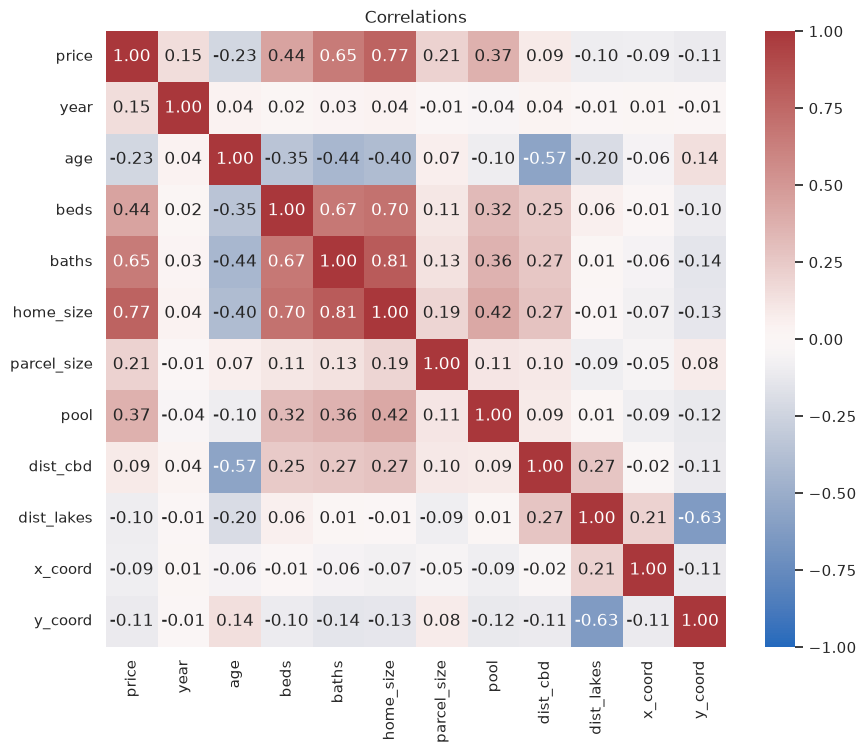

In [3]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Correlations")
plt.show()

## Price vs. home size

Houses are grouped into 250 sq ft size bands. Each line shows the median price in each band, one for houses with a pool and one without; the shaded area covers the middle half of prices. Sizes stop at 5,000 sq ft, where there are still enough houses per band.

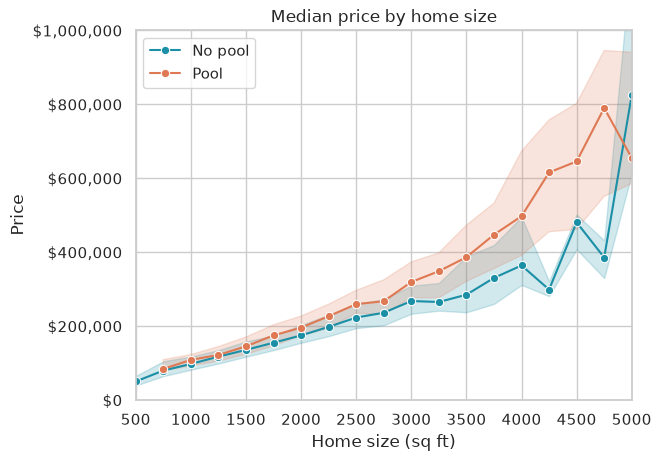

In [4]:
ax = sns.lineplot(x=df["home_size"] // 250 * 250, y=df["price"], hue=df["pool"],
                  palette={0: "#1A8FA6", 1: "#DF7953"}, estimator="median", errorbar=("pi", 50), marker="o")
ax.legend(ax.get_legend().legend_handles, ["No pool", "Pool"], title="")
ax.yaxis.set_major_formatter("${x:,.0f}")
ax.set(title="Median price by home size", xlabel="Home size (sq ft)", ylabel="Price", xlim=(500, 5000), ylim=(0, 1_000_000))
plt.show()

## Price by number of bathrooms

Each box covers the middle half of prices for houses with that many bathrooms; the line inside is the median. Only bathroom counts with at least 50 houses are shown, and extreme prices are hidden so the boxes are readable.

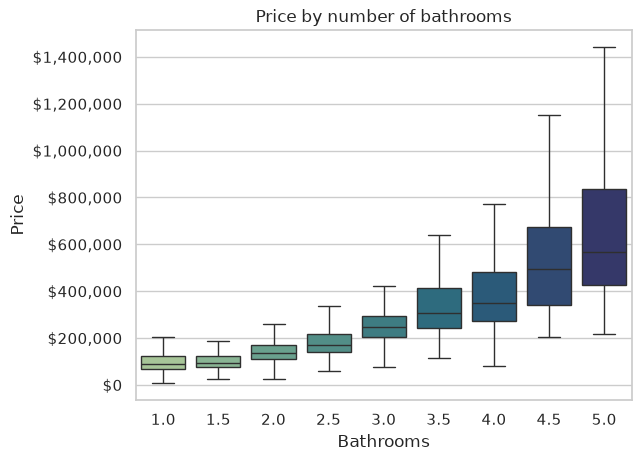

In [5]:
common_baths = [1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5]

ax = sns.boxplot(data=df[df["baths"].isin(common_baths)], x="baths", y="price", hue="baths",
                 palette="crest", legend=False, showfliers=False)
ax.yaxis.set_major_formatter("${x:,.0f}")
ax.set(title="Price by number of bathrooms", xlabel="Bathrooms", ylabel="Price")
plt.show()

## Price by year sold

The median sale price for each year from 2000 to 2005; the shaded area covers the middle half of prices. 2005 has fewer sales in the data (553) than the other years.

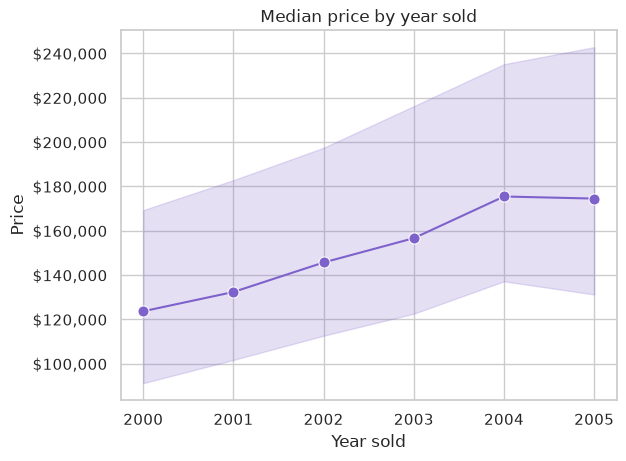

In [6]:
ax = sns.lineplot(data=df, x="year", y="price", estimator="median", errorbar=("pi", 50),
                  marker="o", markersize=8, color="#7E62CC")
ax.yaxis.set_major_formatter("${x:,.0f}")
ax.set(title="Median price by year sold", xlabel="Year sold", ylabel="Price")
plt.show()

## Training

Predict house price by selecting best model

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

models = {
    "LinearRegression": LinearRegression(),
    "XGBRegressor": XGBRegressor(),
    "RandomForestRegressor": RandomForestRegressor()
}


X = df.drop("price", axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)




for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    print(f"R2 Score for: {name}\n{r2:.4f}")



R2 Score for: LinearRegression
0.6480
R2 Score for: XGBRegressor
0.8712
R2 Score for: RandomForestRegressor
0.8353
